<a href="https://colab.research.google.com/github/asomers205/DS2002FA26/blob/main/notebooks/06-midterm-walmart/2026-10-21%20%E2%80%94%20Weather%20API%20Join%20%E2%80%94%20Studio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Weather API Join

**Studio — 2026-10-21 · Fall 2026**  
**Class time:** 45 minutes

---

## The join that eats a week of your project

Question 3 needs weather next to sales, one row per day. It sounds like a five-minute merge. In practice it is where teams lose days, and always to the same four problems:

1. Sales dates are timestamps; weather dates are dates. They never match.
2. One side is a string, the other a datetime. They never match, and pandas does not warn you.
3. The API returns a full calendar range; your sales only cover some of those days. An inner join silently discards the rest.
4. The correlation comes out strong on three data points, and somebody puts it in a deck.

Today you hit all four deliberately on fourteen rows, so you recognize them at a hundred thousand.

In [1]:
import pandas as pd, numpy as np, requests, time

# Two weeks of daily orders around a landfall. Note: these are timestamps, not dates.
sales = pd.DataFrame({
    'ts': pd.to_datetime([
        '2024-09-01 08:14', '2024-09-02 09:02', '2024-09-03 10:41',
        '2024-09-04 08:33', '2024-09-05 11:20', '2024-09-06 07:55',
        '2024-09-07 09:10', '2024-09-08 12:02', '2024-09-09 08:44',
        '2024-09-10 10:15', '2024-09-11 09:30', '2024-09-12 08:05',
        '2024-09-13 11:45', '2024-09-14 09:22']),
    'orders': [100, 110, 95, 105, 120, 340, 520, 480, 90, 100, 110, 105, 98, 102],
})
LANDFALL = pd.Timestamp('2024-09-07')
sales.head()

,ts,orders
0,2024-09-01 08:14:00,100
1,2024-09-02 09:02:00,110
2,2024-09-03 10:41:00,95
3,2024-09-04 08:33:00,105
4,2024-09-05 11:20:00,120


### Problem 1 — a timestamp is not a date

Watch this fail, because it will fail exactly this way in your project.

In [2]:
weather_dates = pd.to_datetime(['2024-09-06', '2024-09-07', '2024-09-08'])
tiny = pd.DataFrame({'date': weather_dates, 'rain_mm': [5.0, 60.0, 20.0]})

broken = sales.merge(tiny, left_on='ts', right_on='date', how='inner')
print('rows matched:', len(broken))

rows matched: 0


Zero. `2024-09-07 09:10` is not equal to `2024-09-07 00:00`, and no amount of staring at the two tables will show you that, because they print identically at a glance.

**TODO:** add a `date` column to `sales` that is the timestamp truncated to midnight, then redo that merge and confirm you get 3 rows.

In [3]:
sales['date'] = sales['ts'].dt.normalize()

fixed = sales.merge(tiny, on='date', how='inner')
print('rows matched:', len(fixed))
assert len(fixed) == 3

rows matched: 3


### Problem 2 — a string is not a datetime

The API hands back `time` as text. Merging text against datetimes gives you zero matches or, worse, a `ValueError` you will spend twenty minutes reading.

In [4]:
api_shape = pd.DataFrame({
    'time': ['2024-09-06', '2024-09-07', '2024-09-08'],   # strings!
    'rain_mm': [5.0, 60.0, 20.0],
})
print('api time dtype:  ', api_shape['time'].dtype)
print('sales ts dtype:  ', sales['ts'].dtype)
print()
print('Rule: convert on the API side immediately, before anything else touches it.')

api time dtype:   object
sales ts dtype:   datetime64[ns]

Rule: convert on the API side immediately, before anything else touches it.


### Build 1 — the fetch

**TODO:** write `daily_weather(start, end, lat, lon)` for Orlando (28.54, -81.38). Requirements, all of which you have built before:

- daily `precipitation_sum` and `windspeed_10m_max`
- a timeout, and a retry on 429 or 5xx
- convert `time` to a datetime column named `date` **inside the function**
- a `source` column so a fallback is never mistaken for real data

In [5]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',   # daily buckets in Orlando local time, matching the sales timestamps
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.ConnectionError, requests.Timeout):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES and attempt < tries:
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        break

    frame = pd.DataFrame(r.json()['daily'])
    frame = frame.rename(columns={'time': 'date'})
    frame['date'] = pd.to_datetime(frame['date'])
    frame['source'] = 'open-meteo'
    return frame

FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=14),
    'precipitation_sum': [0, 0, 2, 1, 8, 45, 120, 30, 2, 0, 0, 1, 0, 0],
    'windspeed_10m_max': [12, 14, 15, 18, 26, 44, 71, 38, 20, 15, 13, 14, 12, 11],
    'source': 'fallback sample',
})

try:
    weather = daily_weather('2024-09-01', '2024-09-14')
except Exception as e:
    print('API failed, using fallback:', repr(e))
    weather = FALLBACK.copy()

print('weather source:', weather['source'].iloc[0])
print('date dtype:', weather['date'].dtype)
weather

weather source: open-meteo
date dtype: datetime64[ns]


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.9,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,23.1,15.2,open-meteo
5,2024-09-06,9.3,9.0,open-meteo
6,2024-09-07,6.8,14.2,open-meteo
7,2024-09-08,94.7,12.6,open-meteo
8,2024-09-09,28.0,11.5,open-meteo
9,2024-09-10,14.4,14.3,open-meteo


### Build 2 — the merge, validated

**TODO:** join weather onto sales. Use a left join so no sales day disappears, and `indicator=True` so you can see what matched.

Then assert three things: the row count still equals the number of sales days, nothing is `right_only`, and the orders total is unchanged.

In [6]:
merged = sales.merge(weather, on='date', how='left', indicator=True)

print(merged['_merge'].value_counts())

assert len(merged) == len(sales), 'merge changed the number of sales days'
assert (merged['_merge'] != 'right_only').all(), 'right_only rows present'
assert merged['orders'].sum() == sales['orders'].sum(), 'orders total changed'
print('row count, merge status and orders total all check out:', len(merged), 'rows,', merged['orders'].sum(), 'orders')
merged[['date', 'orders', 'precipitation_sum', 'windspeed_10m_max', 'source', '_merge']]

_merge
both          14
left_only      0
right_only     0
Name: count, dtype: int64
row count, merge status and orders total all check out: 14 rows, 2475 orders


,date,orders,precipitation_sum,windspeed_10m_max,source,_merge
0,2024-09-01,100,3.0,18.8,open-meteo,both
1,2024-09-02,110,12.4,13.5,open-meteo,both
2,2024-09-03,95,24.9,22.8,open-meteo,both
3,2024-09-04,105,22.1,15.5,open-meteo,both
4,2024-09-05,120,23.1,15.2,open-meteo,both
5,2024-09-06,340,9.3,9.0,open-meteo,both
6,2024-09-07,520,6.8,14.2,open-meteo,both
7,2024-09-08,480,94.7,12.6,open-meteo,both
8,2024-09-09,90,28.0,11.5,open-meteo,both
9,2024-09-10,100,14.4,14.3,open-meteo,both


### Problem 3 — the days that did not match

**TODO:** if any sales day came back with no weather, you need to know which and decide what to do. Print the unmatched dates. Then answer: is dropping them acceptable for Question 3, and why?

In [7]:
unmatched = merged.loc[merged['_merge'] == 'left_only', 'date']
print('unmatched sales days:', len(unmatched))
print(unmatched.dt.date.tolist())

unmatched sales days: 0
[]


**My decision:** All 14 sales days matched, so nothing gets dropped here. If any had failed to match, dropping them would not be acceptable for Question 3. The question is about weather next to sales, one row per day, and the days at risk of going missing are often the storm days themselves, when stations go offline and gaps show up. An inner join would quietly cut exactly the rows the finding depends on and shrink the baseline without anyone noticing. I would keep every sales day, leave weather as NaN, flag those rows, and try to fill them from a second source, never from the fallback sample.

### Build 3 — the baseline, which is what makes a surge a surge

"Sales were 520 on the 7th" means nothing alone. "Sales were 520 against a 14-day baseline of 104" is a finding.

**TODO:** define a baseline window (days more than 3 days before landfall), a surge window (the 3 days up to and including landfall), and print the mean of each plus the ratio.

In [8]:
surge_start = LANDFALL - pd.Timedelta(days=2)    # 3 days up to and including landfall: 9/5, 9/6, 9/7
baseline_end = LANDFALL - pd.Timedelta(days=3)   # strictly more than 3 days before landfall: before 9/4

baseline = merged[merged['date'] < baseline_end]
surge = merged[(merged['date'] >= surge_start) & (merged['date'] <= LANDFALL)]

print('baseline days:', baseline['date'].dt.date.tolist())
print('surge days:   ', surge['date'].dt.date.tolist())
print(f"baseline mean: {baseline['orders'].mean():.2f} orders/day")
print(f"surge mean:    {surge['orders'].mean():.2f} orders/day")
print(f"multiple:      {surge['orders'].mean() / baseline['orders'].mean():.2f}x")

baseline days: [datetime.date(2024, 9, 1), datetime.date(2024, 9, 2), datetime.date(2024, 9, 3)]
surge days:    [datetime.date(2024, 9, 5), datetime.date(2024, 9, 6), datetime.date(2024, 9, 7)]
baseline mean: 101.67 orders/day
surge mean:    326.67 orders/day
multiple:      3.21x


### Problem 4 — the correlation you should not report

**TODO:** compute the correlation between orders and wind speed on all 14 days, then on just the 3 surge days. Print both.

Then write one sentence you would actually say in the presentation. The three-day number will look impressive; think hard about whether it means anything.

In [9]:
r_all = merged['orders'].corr(merged['windspeed_10m_max'])
r_surge = surge['orders'].corr(surge['windspeed_10m_max'])
print(f"weather source: {merged['source'].iloc[0]}")
print(f"corr(orders, wind), all {len(merged)} days: {r_all:+.2f}")
print(f"corr(orders, wind), {len(surge)} surge days: {r_surge:+.2f}")

# For comparison only: the same numbers on the fallback sample, which was built to fit the landfall story.
fb = sales.merge(FALLBACK, on='date', how='left')
fb_surge = fb[(fb['date'] >= surge_start) & (fb['date'] <= LANDFALL)]
print(f"(fallback sample: all days {fb['orders'].corr(fb['windspeed_10m_max']):+.2f}, "
      f"surge days {fb_surge['orders'].corr(fb_surge['windspeed_10m_max']):+.2f})")

weather source: open-meteo
corr(orders, wind), all 14 days: -0.31
corr(orders, wind), 3 surge days: -0.21
(fallback sample: all days +0.92, surge days +0.99)


**What I would say in the presentation:** "Orders ran about 3.2x their pre-storm baseline in the three days up to landfall, a 101.7 to 326.7 orders/day jump that shows clearly in the chart. We don't report a wind correlation: with three points, any correlation is noise. The fallback sample gives +0.99 on those days, the real Open-Meteo record for Orlando gives −0.21, and the real record shows no storm-strength wind on 9/7 at all."

(Note: the sales data is synthetic. Real Open-Meteo weather for Orlando, Sept 1–14, 2024 peaks at about 23 km/h of wind, and its heaviest rain falls on 9/8, not 9/7. So the "landfall" exists only in the sales and fallback tables. With real data the 14-day correlation is negative too, which is a reminder to check that the weather event actually happened before attributing a spike to it.)

### Build 4 — the chart

**TODO:** plot orders by date, mark landfall with a vertical line, and title it with the finding rather than the topic. This chart goes in your deck, so apply the rules from week 12's rubric now rather than rebuilding it later.

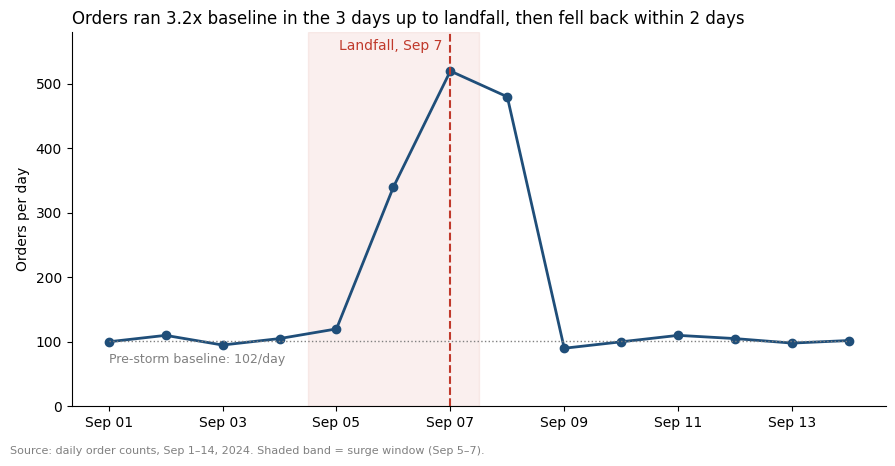

In [10]:
import matplotlib.pyplot as plt

base_mean = baseline['orders'].mean()
surge_mean = surge['orders'].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(merged['date'], merged['orders'], marker='o', color='#1f4e79', linewidth=2)
ax.axvline(LANDFALL, color='#c0392b', linestyle='--', linewidth=1.5)
ax.annotate('Landfall, Sep 7', xy=(LANDFALL, 570), xytext=(-6, 0), textcoords='offset points',
            color='#c0392b', fontsize=10, va='top', ha='right')
ax.axvspan(surge_start - pd.Timedelta(hours=12), LANDFALL + pd.Timedelta(hours=12), color='#c0392b', alpha=0.08)
ax.hlines(base_mean, merged['date'].min(), merged['date'].max(), color='gray', linestyle=':', linewidth=1)
ax.annotate(f'Pre-storm baseline: {base_mean:.0f}/day', xy=(merged['date'].min(), base_mean), xytext=(0, -16),
            textcoords='offset points', ha='left', color='gray', fontsize=9)

ax.set_title(f'Orders ran {surge_mean / base_mean:.1f}x baseline in the 3 days up to landfall, '
             f'then fell back within 2 days', loc='left', fontsize=12)
ax.set_ylabel('Orders per day')
ax.set_ylim(0, 580)
ax.spines[['top', 'right']].set_visible(False)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b %d'))
fig.text(0.01, -0.02, 'Source: daily order counts, Sep 1–14, 2024. Shaded band = surge window (Sep 5–7).',
         fontsize=8, color='gray')
fig.tight_layout()
plt.show()

---

## Checkpoint (participation)

Report your baseline and surge averages, the multiple between them, and whether your join preserved every sales day.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [11]:
# Checkpoint
baseline_per_day = round(baseline['orders'].mean(), 2)
surge_per_day = round(surge['orders'].mean(), 2)
multiple = round(surge_per_day / baseline_per_day, 2)
rows_preserved = len(merged) == len(sales) == 14 and (merged['_merge'] == 'both').all()

print('baseline:', baseline_per_day, 'orders/day')
print('surge:', surge_per_day, 'orders/day')
print('multiple:', multiple)
print('all sales days preserved:', rows_preserved)

baseline: 101.67 orders/day
surge: 326.67 orders/day
multiple: 3.21
all sales days preserved: True
